# First look: the baselines, and where Laya and Jev differ

Before the full runs, what is there to beat, and how do Laya and Jev behave on the same products?

1. **The baselines**: what a model gets by always giving the most common answer.
2. **One product**, a butter croissant, where Laya goes wrong, and why.
3. **What Laya reads of the question**: less than we wrote.
4. **The first 1,024 calibration products**: accuracy, what each system answers, where they disagree.
5. **Option order**: the same question with its options reversed.
6. **Confidence**: when each system is sure, how often it is right, and what fitting Laya's temperature can and cannot fix.

Everything after section 1 runs on calibration rows, the split set aside for tuning Laya.
These are not the reported numbers: those come from the evaluation split after the full runs.
The Jev numbers stay inside Xebia until TypeSafe's terms on publishing benchmarks have been read.

Before running: start Laya with `just laya`, and put the Jev key in `.env` as `JEV_API_KEY`.
The runs go through the harness and are kept in `data/runs/`, so running the notebook again only sends the handful of single requests in section 2.
The first run sends about 2,000 requests to Jev, under 10 cents.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import duckdb
import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import Markdown, display

# The notebooks live in notebooks/; every path below is from the project root
os.chdir(next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists()))

assert Path(sys.prefix).resolve() == Path(".venv").resolve(), (
    f"The kernel runs {sys.executable}, not this project's .venv. Start Jupyter with `just lab`."
)
# Laya's tokenizer code imports tqdm, which warns that ipywidgets is missing; no progress bar is shown here
warnings.filterwarnings("ignore", message="IProgress not found")

from laya.agent import Agent
from laya.common import build_head

from harness.client import RequestFailed, SystemOne
from harness.questions import FOOD_GROUP_OPTION, OPTIONS, QUESTIONS, probabilities, read_answer, truth_of
from harness.runs import LAYA_VERSION, SAMPLE, SYSTEMS as ALL_SYSTEMS, build, run
from harness.truncation import Truncation

# The published Laya against Jev; laya-ft, the Laya fine-tuned on the calibration split, comes after training
SYSTEMS = {name: ALL_SYSTEMS[name] for name in ("laya", "jev")}

load_dotenv()

RUN, REVERSED_RUN = "first-look", "first-look-reversed"
SPLIT, ROWS = "calibration", 1_024
NAMES = {"laya": "Laya", "jev": "Jev"}

con = duckdb.connect()

In [2]:
def sql(query: str) -> pd.DataFrame:
    return con.sql(query).df()


def show(df: pd.DataFrame, precision: int = 2) -> None:
    display(df.style.hide(axis="index").format(thousands=",", precision=precision, escape="html"))


def md_escape(text: str) -> str:
    for char in "\\`*_[]<>#|":
        text = text.replace(char, "\\" + char)
    return text


def show_state(state: str, heading: str) -> None:
    lines = "\n".join(f"> {md_escape(line)}  " for line in state.splitlines())
    display(Markdown(f"#### {md_escape(heading)}\n\n{lines}"))


def top(probs: dict[str, float], n: int = 1) -> str:
    """The `n` most likely options with their probabilities, as text."""
    ranked = sorted(probs.items(), key=lambda item: -item[1])[:n]
    return ", ".join(f"{option} {p:.2f}" for option, p in ranked)


async def ask(system: str, state: str, questions: dict = QUESTIONS) -> dict | None:
    """One request to one system; None when the system does not accept the question."""
    settings = SYSTEMS[system]
    api_key = os.environ[settings.api_key_env] if settings.api_key_env else None
    async with SystemOne(settings.base_url, settings.model, api_key, timeout=settings.timeout_s) as client:
        try:
            return (await client.decide(state, questions)).json
        except RequestFailed as refusal:
            if refusal.attempts == 1 and "HTTP 422" in str(refusal):
                return None
            raise


INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
GRAY = "#b5b3aa"
COLOR = {"laya": "#2a78d6", "jev": "#eb6834", "truth": GRAY}

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 120,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10.5,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titlesize": 10.5,
    "axes.titlecolor": INK_2,
    "axes.titlepad": 10,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": AXIS,
    "ytick.color": AXIS,
    "xtick.labelcolor": MUTED,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})


def percent_axis(ax, axis: str = "x") -> None:
    getattr(ax, f"{axis}axis").set_major_formatter(lambda value, _: f"{value:.0%}")


def mosaic(height: float = 4.8):
    """food_group on the left, the two short questions stacked on the right."""
    return plt.subplot_mosaic(
        [["food_group", "ultra_processed"], ["food_group", "nutriscore"]],
        figsize=(10, height), layout="constrained", width_ratios=[3, 2], height_ratios=[1, 2.2],
    )

## 1. The baselines

A model has to beat two simple strategies: guessing at random, and always giving the most common answer, the majority baseline.
Both come from the labels alone, so they can be measured on the evaluation split without asking either system anything.

In [3]:
labels = sql(f"SELECT food_group, ultra_processed, nutriscore FROM read_parquet('{SAMPLE}') WHERE split = 'evaluation'")
evaluation_truth = pd.DataFrame([truth_of(*row) for row in labels.itertuples(index=False)])
evaluation_shares = {
    question: evaluation_truth[question].value_counts(normalize=True).reindex(OPTIONS[question], fill_value=0)
    for question in QUESTIONS
}

show(pd.DataFrame([
    {
        "question": question,
        "options": len(OPTIONS[question]),
        "random guess": f"{1 / len(OPTIONS[question]):.0%}",
        "majority answer": shares.idxmax(),
        "majority baseline": f"{shares.max():.1%}",
    }
    for question, shares in evaluation_shares.items()
]))

question,options,random guess,majority answer,majority baseline
food_group,10,10%,sugary snacks,23.3%
ultra_processed,2,50%,yes,67.0%
nutriscore,5,20%,E,30.8%


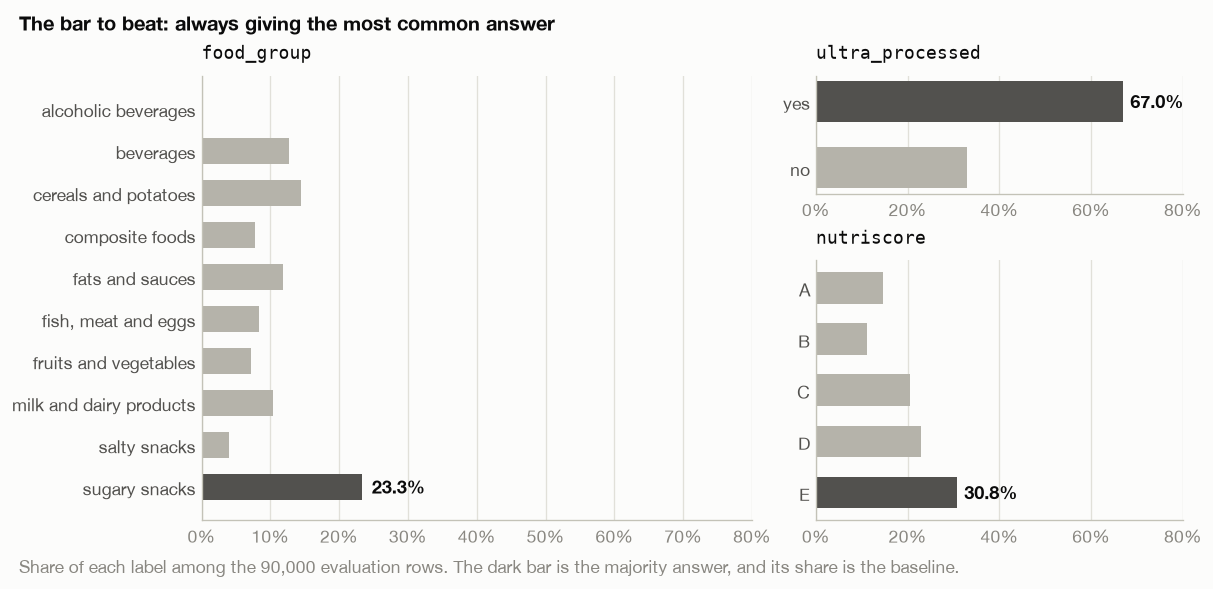

In [4]:
fig, axes = mosaic()
for question, ax in axes.items():
    shares = evaluation_shares[question]
    majority = shares.idxmax()
    ax.barh(range(len(shares)), shares.values, height=0.62,
            color=[INK_2 if option == majority else GRAY for option in shares.index])
    ax.text(shares.max() + 0.015, list(shares.index).index(majority), f"{shares.max():.1%}",
            va="center", color=INK, fontweight="bold")
    ax.set_yticks(range(len(shares)), shares.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.8)
    percent_axis(ax)
    ax.tick_params(length=0)
    ax.grid(axis="y", visible=False)
    ax.set_title(question, fontfamily="monospace", color=INK)

fig.suptitle("The bar to beat: always giving the most common answer", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.supxlabel(f"Share of each label among the {len(labels):,} evaluation rows. "
              "The dark bar is the majority answer, and its share is the baseline.",
              x=0.01, ha="left", color=MUTED, fontsize=10.5)
plt.show()

- `food_group` is the hard one for a baseline: the most common group covers less than a quarter of the products.
- `ultra_processed` has a high baseline: two thirds of the products are NOVA 4, so a system that always says "yes" is right two times out of three.
- `nutriscore` has five grades and no dominant one, but it is a formula over the nutrition numbers, which both systems are known to read poorly.

## 2. One product: a butter croissant

A product written the way the sample writes its states, so its expected answers are clear:

- `food_group`: sugary snacks, whose description in the question lists "cakes and pastries";
- `ultra_processed`: yes, because mono- and diglycerides of fatty acids (E471) are one of the additives that make a product NOVA 4;
- `nutriscore`: D or E, depending on the version of the formula: saturated fat, energy and salt all score high.

In [5]:
CROISSANT = """Product: Butter croissant
Ingredients: wheat flour, butter (milk) 25%, water, sugar, yeast, eggs, salt, wheat gluten, emulsifier: mono- and diglycerides of fatty acids.
Nutrition per 100 g: energy 420 kcal, fat 23 g, saturated fat 15 g, sugars 8 g, salt 1.1 g, fibre 2 g, proteins 8 g"""
EXPECTED = {"food_group": "sugary snacks", "ultra_processed": "yes", "nutriscore": "D or E"}

show_state(CROISSANT, "Butter croissant")
croissant = {}
for system in SYSTEMS:
    croissant[system] = await ask(system, CROISSANT)

rows = []
for question in QUESTIONS:
    row = {"question": question, "expected": EXPECTED[question]}
    for system, response in croissant.items():
        probs = probabilities(response["answers"][question], question)
        row[NAMES[system]] = top(probs, 3 if question == "food_group" and system == "laya" else 1)
    rows.append(row)
show(pd.DataFrame(rows))

#### Butter croissant

> Product: Butter croissant  
> Ingredients: wheat flour, butter (milk) 25%, water, sugar, yeast, eggs, salt, wheat gluten, emulsifier: mono- and diglycerides of fatty acids.  
> Nutrition per 100 g: energy 420 kcal, fat 23 g, saturated fat 15 g, sugars 8 g, salt 1.1 g, fibre 2 g, proteins 8 g  

question,expected,Laya,Jev
food_group,sugary snacks,"fats and sauces 0.23, sugary snacks 0.22, milk and dairy products 0.21",sugary snacks 0.84
ultra_processed,yes,no 0.61,yes 0.76
nutriscore,D or E,B 0.53,D 0.58


Jev gets the food group right with a clear margin.
Laya's three most likely groups are within a few points of each other: it is not choosing, it is close to guessing.
When a model is that close to a tie, small changes to the input decide the answer.
Here is the same `food_group` question with one thing changed at a time:

In [6]:
food_group = QUESTIONS["food_group"]
reversed_options = {**food_group, "criteria": dict(reversed(food_group["criteria"].items()))}
names_only = {**food_group, "criteria": list(food_group["criteria"])}

PROBES = [
    ("as asked", CROISSANT, food_group),
    ("options in reverse order", CROISSANT, reversed_options),
    ("option names only, no descriptions", CROISSANT, names_only),
    ("product name only", CROISSANT.splitlines()[0], food_group),
    ("without the nutrition line", "\n".join(CROISSANT.splitlines()[:2]), food_group),
]

rows = []
for change, state, question in PROBES:
    row = {"change": change}
    for system in SYSTEMS:
        response = await ask(system, state, {"food_group": question})
        row[NAMES[system]] = (top(probabilities(response["answers"]["food_group"], "food_group"))
                              if response else "not accepted: needs a description per option")
    rows.append(row)
show(pd.DataFrame(rows))

change,Laya,Jev
as asked,fats and sauces 0.23,sugary snacks 0.87
options in reverse order,sugary snacks 0.34,sugary snacks 0.76
"option names only, no descriptions",milk and dairy products 0.91,not accepted: needs a description per option
product name only,sugary snacks 0.30,sugary snacks 0.77
without the nutrition line,milk and dairy products 0.30,sugary snacks 0.85


Laya's answer moves with the option order, the descriptions, and the parts of the state it is shown.
With the ingredients in view it picks up "butter (milk)" and leans to fats or dairy; from the name alone it says sugary snacks.
Jev gives the same answer every time.

## 3. What Laya reads of the question

Laya puts the question in front of the product, with one span per option, and gives the whole question at most 192 of its 512 tokens.
With ten options that is 17 tokens per option, so it cuts the descriptions we wrote.
Jev reads them in full.

In [7]:
REVISION = httpx.get(f"{SYSTEMS['laya'].base_url}/health").json()["revisions"][SYSTEMS["laya"].model]
counter = Truncation(REVISION, LAYA_VERSION)
head, markers, stats = build_head(counter.tok, Agent._to_internal(food_group), counter.head_max_len)
ends = [*markers[1:], len(head) - 1]  # an option runs to the next one's [MASK]; the last one to the closing [SEP]

rows = []
for (option, description), start, end in zip(food_group["criteria"].items(), markers, ends, strict=True):
    wrote = f"{option}: {description}"
    read = counter.tok.decode(head[start + 1:end], clean_up_tokenization_spaces=False).strip()
    rows.append({"we wrote": wrote, "Laya reads": read, "complete": "yes" if read == wrote else "cut"})
show(pd.DataFrame(rows))
print(f"{stats['tokens_per_option']} tokens per option, {len(head)} tokens for the whole question")

we wrote,Laya reads,complete
"alcoholic beverages: beer, wine, cider, spirits and other drinks with alcohol","alcoholic beverages: beer, wine, cider, spirits and other drinks with alcohol",yes
"beverages: non-alcoholic drinks: sodas, juices and nectars, waters, teas and coffees, plant-based milk substitutes","beverages: non-alcoholic drinks: sodas, juices and nect",cut
"cereals and potatoes: bread, breakfast cereals, pasta, rice and other cereals, legumes and potatoes","cereals and potatoes: bread, breakfast cereals, pasta, rice and other",cut
"composite foods: ready meals, pizzas, pies, quiches and sandwiches","composite foods: ready meals, pizzas, pies, quiches",cut
"fats and sauces: dressings and sauces, oils, butter, margarine and other fats","fats and sauces: dressings and sauces, oils, butter, marg",cut
"fish, meat and eggs: meat, processed meat, fish and seafood, eggs","fish, meat and eggs: meat, processed meat, fish and seafood, eggs",yes
"fruits and vegetables: fruits, vegetables, dried fruits and soups","fruits and vegetables: fruits, vegetables, dried fruits and soups",yes
"milk and dairy products: milk, yogurt, cheese, dairy desserts and ice cream","milk and dairy products: milk, yogurt, cheese, dairy desserts and ice",cut
"salty snacks: crisps, crackers and other appetizers, nuts, salty and fatty snacks","salty snacks: crisps, crackers and other appetizers, nuts,",cut
"sugary snacks: sweets, chocolate, biscuits, cakes and pastries","sugary snacks: sweets, chocolate, biscuits, cakes and pastries",yes


17 tokens per option, 182 tokens for the whole question


Most descriptions lose their last words, and some lose the examples that would settle a product: "sandwiches" for composite foods, "ice cream" for dairy.
"fats and sauces" keeps "butter", which is exactly the word in the croissant's ingredients.

## 4. The first 1,024 calibration products

Both systems answer the same products through the harness, exactly as the full run will send them.

In [8]:
for system in SYSTEMS:
    await run(system, RUN, split=SPLIT, limit=ROWS)

sample = sql(f"""
    SELECT id, name, food_group, ultra_processed, nutriscore
    FROM read_parquet('{SAMPLE}') WHERE split = '{SPLIT}' ORDER BY id LIMIT {ROWS}
""")
truth = {row.id: truth_of(row.food_group, row.ultra_processed, row.nutriscore) for row in sample.itertuples()}
name_of = dict(zip(sample.id, sample.name))


def load(run_name: str) -> pd.DataFrame:
    frame = sql(f"FROM '{build(run_name)}'")
    assert frame.error.isna().all(), f"{frame.error.notna().sum()} failed rows in {run_name}"
    frame["truth"] = [truth[id][question] for id, question in zip(frame.id, frame.question)]
    frame["right"] = frame.answer == frame.truth
    frame["confidence"] = [probs[answer] for probs, answer in zip(frame.probs, frame.answer)]
    return frame


answers = load(RUN)
print(f"{answers.id.nunique():,} products, {len(answers):,} answers, no failed request")

laya: 0 of 1,024 products to send to laya 0.4.18, english@7b928d8


jev: 0 of 1,024 products to send to jev-1.14.0


1,024 products, 6,144 answers, no failed request


### Accuracy

In [9]:
baseline = {question: pd.Series([truth[id][question] for id in truth]).value_counts(normalize=True).max()
            for question in QUESTIONS}
accuracy = answers.pivot_table(index="question", columns="system", values="right", aggfunc="mean").reindex(list(QUESTIONS))

show(pd.DataFrame({
    "question": list(QUESTIONS),
    "Laya": [f"{accuracy.loc[question, 'laya']:.1%}" for question in QUESTIONS],
    "Jev": [f"{accuracy.loc[question, 'jev']:.1%}" for question in QUESTIONS],
    "majority baseline": [f"{baseline[question]:.1%}" for question in QUESTIONS],
    "random guess": [f"{1 / len(OPTIONS[question]):.0%}" for question in QUESTIONS],
}))

question,Laya,Jev,majority baseline,random guess
food_group,52.0%,86.2%,23.0%,10%
ultra_processed,62.5%,89.6%,64.5%,50%
nutriscore,13.8%,52.3%,28.3%,20%


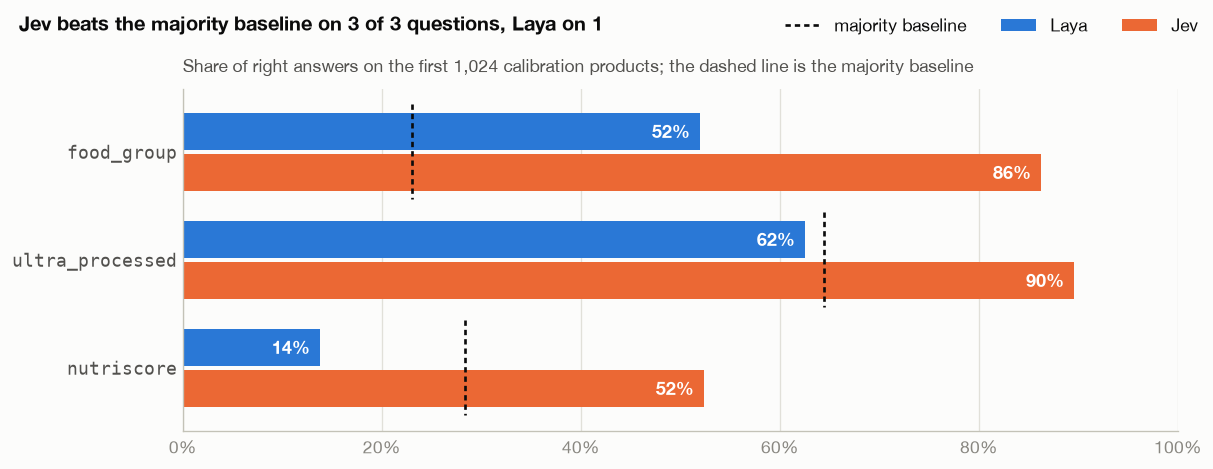

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
for row, question in enumerate(QUESTIONS):
    for offset, system in ((-0.19, "laya"), (0.19, "jev")):
        value = accuracy.loc[question, system]
        ax.barh(row + offset, value, height=0.34, color=COLOR[system], label=NAMES[system] if row == 0 else None)
        ax.text(value - 0.01, row + offset, f"{value:.0%}", va="center", ha="right", color="white",
                fontweight="bold")
    ax.plot([baseline[question]] * 2, [row - 0.44, row + 0.44], color=INK, linewidth=1.6,
            linestyle=(0, (2, 1.5)), label="majority baseline" if row == 0 else None)
ax.set_yticks(range(len(QUESTIONS)), list(QUESTIONS), fontfamily="monospace")
ax.invert_yaxis()
ax.set_xlim(0, 1)
percent_axis(ax)
ax.tick_params(length=0)
ax.grid(axis="y", visible=False)
fig.legend(loc="outside upper right", ncols=3)

beats = {system: sum(accuracy.loc[q, system] > baseline[q] for q in QUESTIONS) for system in SYSTEMS}
fig.suptitle(f"Jev beats the majority baseline on {beats['jev']} of 3 questions, Laya on {beats['laya']}",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
ax.set_title(f"Share of right answers on the first {ROWS:,} calibration products; the dashed line is the majority baseline")
plt.show()

### What each system answers

A model can reach a decent accuracy and still lean on a few answers.
Here is how often each option is the truth, Laya's answer and Jev's answer:

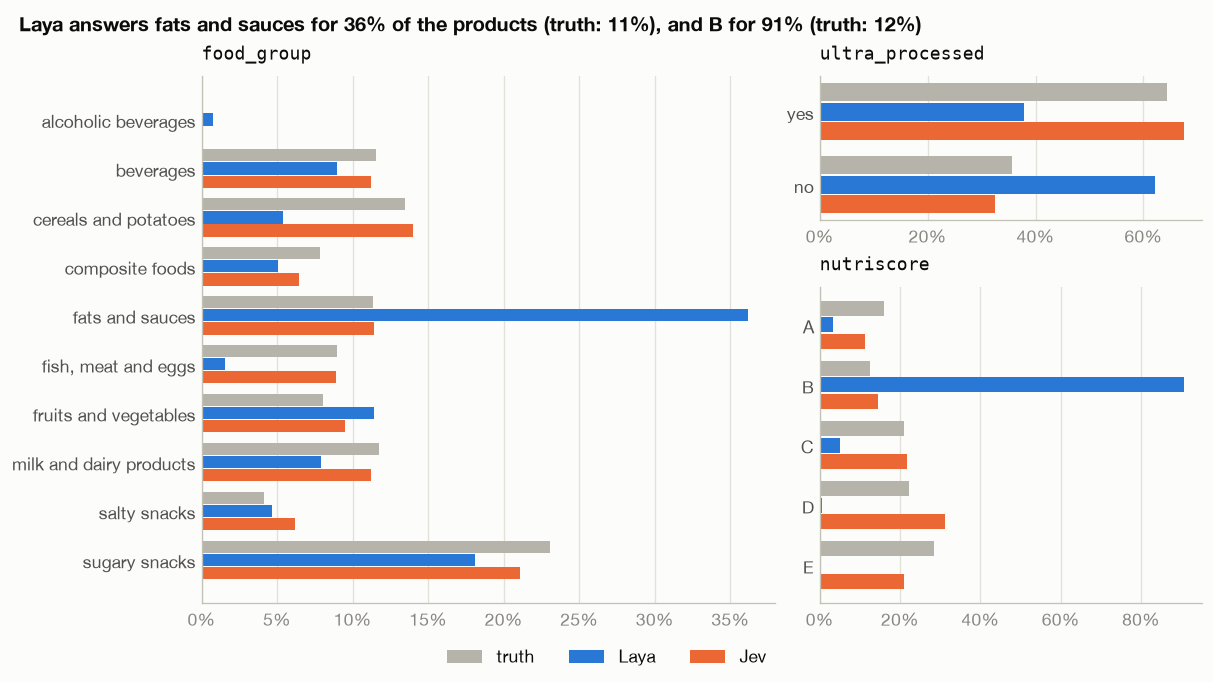

question,option,truth,Laya,Jev
food_group,alcoholic beverages,0.0%,0.8%,0.1%
food_group,beverages,11.5%,9.0%,11.2%
food_group,cereals and potatoes,13.5%,5.4%,14.0%
food_group,composite foods,7.8%,5.1%,6.4%
food_group,fats and sauces,11.3%,36.1%,11.4%
food_group,"fish, meat and eggs",9.0%,1.6%,8.9%
food_group,fruits and vegetables,8.0%,11.4%,9.5%
food_group,milk and dairy products,11.7%,7.9%,11.2%
food_group,salty snacks,4.1%,4.7%,6.2%
food_group,sugary snacks,23.0%,18.1%,21.1%


In [11]:
def answer_shares(question: str) -> pd.DataFrame:
    rows = answers[answers.question == question]
    shares = {"truth": rows[rows.system == "laya"].truth.value_counts(normalize=True)}
    for system in SYSTEMS:
        shares[system] = rows[rows.system == system].answer.value_counts(normalize=True)
    return pd.DataFrame(shares).reindex(OPTIONS[question]).fillna(0)


shares = {question: answer_shares(question) for question in QUESTIONS}

fig, axes = mosaic(height=5.6)
for question, ax in axes.items():
    frame = shares[question]
    for offset, column in ((-0.27, "truth"), (0, "laya"), (0.27, "jev")):
        ax.barh(np.arange(len(frame)) + offset, frame[column], height=0.25, color=COLOR[column],
                label={"truth": "truth", **NAMES}[column])
    ax.set_yticks(range(len(frame)), frame.index)
    ax.invert_yaxis()
    percent_axis(ax)
    ax.tick_params(length=0)
    ax.grid(axis="y", visible=False)
    ax.set_title(question, fontfamily="monospace", color=INK)
handles, names = axes["food_group"].get_legend_handles_labels()
fig.legend(handles, names, loc="outside lower center", ncols=3)

lean = {question: (shares[question].laya - shares[question].truth).idxmax() for question in ("food_group", "nutriscore")}
fig.suptitle(
    f"Laya answers {lean['food_group']} for {shares['food_group'].laya[lean['food_group']]:.0%} of the products "
    f"(truth: {shares['food_group'].truth[lean['food_group']]:.0%}), "
    f"and {lean['nutriscore']} for {shares['nutriscore'].laya[lean['nutriscore']]:.0%} "
    f"(truth: {shares['nutriscore'].truth[lean['nutriscore']]:.0%})",
    x=0.01, ha="left", fontweight="bold", fontsize=12,
)
plt.show()

table = pd.concat([frame.rename_axis("option").reset_index().assign(question=question)
                   for question, frame in shares.items()])
show(pd.DataFrame({
    "question": table.question,
    "option": table.option,
    "truth": table.truth.map("{:.1%}".format),
    "Laya": table.laya.map("{:.1%}".format),
    "Jev": table.jev.map("{:.1%}".format),
}))

### Where they agree, and where they do not

In [12]:
paired = answers.pivot_table(index=["id", "question"], columns="system", values="right", aggfunc="first").reset_index()
show(pd.DataFrame([
    {
        "question": question,
        "both right": f"{(group.laya & group.jev).mean():.0%}",
        "only Jev right": f"{(~group.laya & group.jev).mean():.0%}",
        "only Laya right": f"{(group.laya & ~group.jev).mean():.0%}",
        "both wrong": f"{(~group.laya & ~group.jev).mean():.0%}",
    }
    for question, group in paired.assign(laya=paired.laya.astype(bool), jev=paired.jev.astype(bool))
    .groupby("question", sort=False)
]))

question,both right,only Jev right,only Laya right,both wrong
food_group,50%,36%,2%,12%
nutriscore,5%,47%,8%,39%
ultra_processed,57%,32%,5%,5%


Products Laya put in its most over-used food group while Jev got them right, the first eight by id:

In [13]:
food = answers[answers.question == "food_group"].pivot_table(
    index="id", columns="system", values=["answer", "confidence", "truth"], aggfunc="first"
)
food.columns = [f"{value}_{system}" for value, system in food.columns]
food = food.reset_index()


def examples(selection: pd.DataFrame, n: int = 8) -> pd.DataFrame:
    return pd.DataFrame({
        "id": selection.id,
        "product": selection.id.map(name_of),
        "truth": selection.truth_laya,
        "Laya": [f"{answer} {p:.2f}" for answer, p in zip(selection.answer_laya, selection.confidence_laya)],
        "Jev": [f"{answer} {p:.2f}" for answer, p in zip(selection.answer_jev, selection.confidence_jev)],
    }).head(n)


show(examples(food[(food.answer_laya == lean["food_group"]) & (food.truth_laya != lean["food_group"])
                   & (food.answer_jev == food.truth_laya)]))

id,product,truth,Laya,Jev
4,Italian sausage pizza,composite foods,fats and sauces 0.64,composite foods 1.00
7,Oven Roasted Turkey Breast,"fish, meat and eggs",fats and sauces 0.22,"fish, meat and eggs 1.00"
8,Low moisture part skim mozzarella light string,milk and dairy products,fats and sauces 0.22,milk and dairy products 1.00
12,Mini stroopwafels,sugary snacks,fats and sauces 0.67,sugary snacks 1.00
15,CHICKEN SAUSAGE SWEET ITALIAN STYLE,"fish, meat and eggs",fats and sauces 0.49,"fish, meat and eggs 1.00"
21,Fettuccine corn and rice pasta,cereals and potatoes,fats and sauces 0.46,cereals and potatoes 1.00
25,Organic Black Pepper Barilotti Pasta Bronze Cut,cereals and potatoes,fats and sauces 0.32,cereals and potatoes 1.00
30,Costilla de cerdo / Entrecosto de porco,"fish, meat and eggs",fats and sauces 0.80,"fish, meat and eggs 1.00"


And the products Jev got wrong, which show where the label itself is debatable:

In [14]:
show(examples(food[food.answer_jev != food.truth_laya]))

id,product,truth,Laya,Jev
20,Saltines,sugary snacks,fats and sauces 0.26,salty snacks 0.97
23,Peach cobbler a la mode,milk and dairy products,milk and dairy products 0.40,sugary snacks 0.51
24,"Cheese crisp bar, everything cheddar",milk and dairy products,salty snacks 0.44,salty snacks 0.99
26,Mature cheddar coleslaw,salty snacks,fats and sauces 0.63,fruits and vegetables 0.62
28,Fried Potato Chips Cured Cheese Flavor,cereals and potatoes,milk and dairy products 0.55,salty snacks 1.00
29,Black Eyed Pea Salsa,fats and sauces,fats and sauces 0.53,fruits and vegetables 0.63
43,Chinese Noodles & Veggies in a Cashew Cream Sauce,cereals and potatoes,fats and sauces 0.42,composite foods 0.86
46,Chicken Corn Chowder Soup,composite foods,fats and sauces 0.32,fruits and vegetables 0.73


## 5. Option order

The same products and questions again, with only the order of the `food_group` options reversed.
A system that reads the options as a set gives the same answers; one that is biased by position does not.

In [15]:
REVERSED = {**QUESTIONS, "food_group": reversed_options}
for system in SYSTEMS:
    await run(system, REVERSED_RUN, split=SPLIT, limit=ROWS, questions=REVERSED)
reversed_answers = load(REVERSED_RUN)

changed, rows = {}, []
for system in SYSTEMS:
    asked = answers[(answers.system == system) & (answers.question == "food_group")].set_index("id")
    flipped = reversed_answers[(reversed_answers.system == system) & (reversed_answers.question == "food_group")]
    flipped = flipped.set_index("id").reindex(asked.index)
    changed[system] = (asked.answer != flipped.answer).mean()
    rows.append({
        "system": NAMES[system],
        "accuracy, options as asked": f"{asked.right.mean():.1%}",
        "accuracy, options reversed": f"{flipped.right.mean():.1%}",
        "answers that change": f"{changed[system]:.1%}",
    })
show(pd.DataFrame(rows))

laya: 0 of 1,024 products to send to laya 0.4.18, english@7b928d8


jev: 0 of 1,024 products to send to jev-1.14.0


system,"accuracy, options as asked","accuracy, options reversed",answers that change
Laya,52.0%,50.1%,29.7%
Jev,86.2%,85.4%,1.8%


## 6. Confidence, and what calibration can fix

Every answer comes with a probability.
If a system is well calibrated, the answers it gives with 70% confidence are right 70% of the time.
Grouping the `food_group` answers by confidence shows how far each system is from that:

In [16]:
BINS = [0, 0.3, 0.5, 0.7, 0.9, 1.0001]
LABELS = ["under 0.3", "0.3 to 0.5", "0.5 to 0.7", "0.7 to 0.9", "0.9 and up"]
food_answers = answers[answers.question == "food_group"]

reliability = {}
for system in SYSTEMS:
    rows = food_answers[food_answers.system == system]
    reliability[system] = rows.groupby(pd.cut(rows.confidence, BINS, right=False, labels=LABELS), observed=False).agg(
        products=("right", "size"), confidence=("confidence", "mean"), right=("right", "mean")
    )

table = pd.DataFrame({"confidence": LABELS})
for system in SYSTEMS:
    table[f"{NAMES[system]} products"] = reliability[system].products.values
    table[f"{NAMES[system]} right"] = [f"{value:.0%}" if count else "" for value, count
                                       in zip(reliability[system].right, reliability[system].products)]
show(table)

confidence,Laya products,Laya right,Jev products,Jev right
under 0.3,212,31%,0,
0.3 to 0.5,368,38%,12,42%
0.5 to 0.7,216,62%,76,54%
0.7 to 0.9,149,84%,77,62%
0.9 and up,79,87%,859,92%


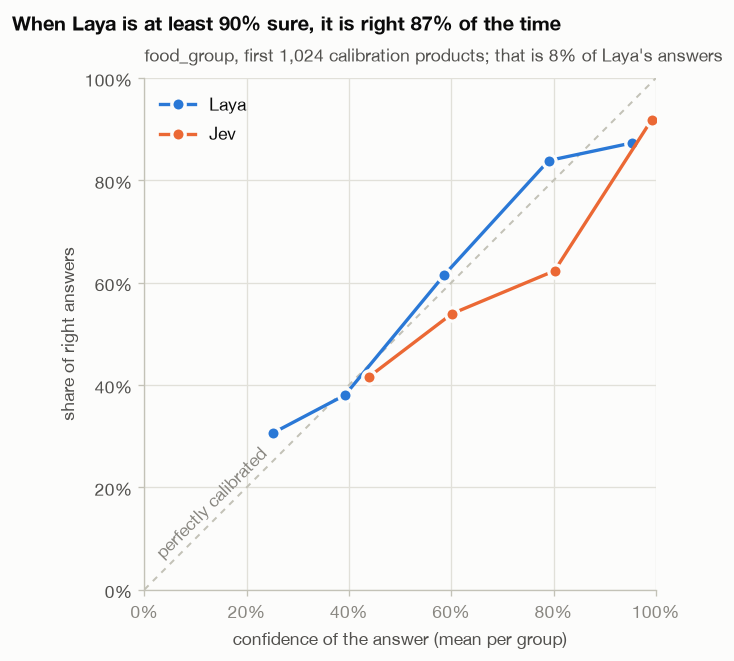

In [17]:
fig, ax = plt.subplots(figsize=(6.6, 5.4), layout="constrained")
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1.2, linestyle=(0, (3, 3)))
ax.text(0.13, 0.17, "perfectly calibrated", rotation=45, color=MUTED, ha="center", va="center")
for system in SYSTEMS:
    points = reliability[system][reliability[system].products > 0]
    ax.plot(points.confidence, points.right, color=COLOR[system], linewidth=2, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=NAMES[system])
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
percent_axis(ax, "x")
percent_axis(ax, "y")
ax.set_xlabel("confidence of the answer (mean per group)")
ax.set_ylabel("share of right answers")
ax.legend(loc="upper left")

laya_food = food_answers[food_answers.system == "laya"]
sure = laya_food.confidence >= 0.9
fig.suptitle(f"When Laya is at least 90% sure, it is right {laya_food.right[sure].mean():.0%} of the time",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
ax.set_title(f"food_group, first {ROWS:,} calibration products; that is {sure.mean():.0%} of Laya's answers")
plt.show()

Both lines rise: the more confident an answer, the more often it is right, for both systems.
That makes the confidence useful even before calibration: answer the products a system is sure about, and send the rest elsewhere.

On `food_group`, Laya's line already runs close to the diagonal.
Jev is the over-confident one here: most of its answers are at least 90% sure, and the ones between 70% and 90% are right less often than it claims.

The other questions look different.
Per question, a system whose average confidence is above its share of right answers is over-confident:

In [18]:
summary = answers.groupby(["question", "system"], sort=False).agg(confidence=("confidence", "mean"), right=("right", "mean"))
verdict, rows = {}, []
for question in QUESTIONS:
    row = {"question": question}
    for system in SYSTEMS:
        confidence, right = summary.loc[(question, system)]
        verdict[question, system] = ("over-confident" if confidence > right + 0.02
                                     else "under-confident" if confidence < right - 0.02 else "about right")
        row[f"{NAMES[system]} confidence"] = f"{confidence:.0%}"
        row[f"{NAMES[system]} right"] = f"{right:.0%}"
        row[NAMES[system]] = verdict[question, system]
    rows.append(row)
show(pd.DataFrame(rows))

question,Laya confidence,Laya right,Laya,Jev confidence,Jev right,Jev
food_group,51%,52%,about right,94%,86%,over-confident
ultra_processed,73%,62%,over-confident,83%,90%,under-confident
nutriscore,53%,14%,over-confident,62%,52%,over-confident


Laya is over-confident where it is weakest, on `ultra_processed` and above all `nutriscore`, which is where fitting its temperature matters.

Fitting Laya's temperature on the calibration split moves its line toward the diagonal, so that a probability means what it says.
It does not change a single answer.
The temperature `T` divides every option's score by the same number before the probabilities are computed, and that never changes which option scores highest.
On the croissant:

In [19]:
laya_croissant = probabilities(croissant["laya"]["answers"]["food_group"], "food_group")
scores = np.log(np.clip(list(laya_croissant.values()), 1e-6, None))  # the scores, up to a constant

rows = []
for temperature in (0.25, 0.5, 1, 2, 4):
    probs = np.exp(scores / temperature)
    probs = dict(zip(laya_croissant, probs / probs.sum()))
    rows.append({"temperature T": temperature, "answer": read_answer(probs), "top three": top(probs, 3)})
show(pd.DataFrame(rows))

temperature T,answer,top three
0.25,fats and sauces,"fats and sauces 0.37, sugary snacks 0.33, milk and dairy products 0.28"
0.50,fats and sauces,"fats and sauces 0.31, sugary snacks 0.29, milk and dairy products 0.27"
1.00,fats and sauces,"fats and sauces 0.23, sugary snacks 0.22, milk and dairy products 0.21"
2.00,fats and sauces,"fats and sauces 0.17, sugary snacks 0.16, milk and dairy products 0.16"
4.00,fats and sauces,"fats and sauces 0.13, sugary snacks 0.13, milk and dairy products 0.13"


`T = 1` is Laya as shipped.
A lower temperature makes Laya surer of `fats and sauces`, a higher one less sure, but the answer stays the same, and so does its accuracy.
What calibration buys is an honest confidence: the croissant's answer becomes a clear "not sure", which is what accuracy against coverage, in the analysis, is built on.

## 7. In short

In [20]:
fg_lean = lean["food_group"]
display(Markdown("\n".join([
    f"- On the first {ROWS:,} calibration products Jev answers `food_group` right {accuracy.loc['food_group', 'jev']:.0%} "
    f"of the time and Laya {accuracy.loc['food_group', 'laya']:.0%}, against a majority baseline of {baseline['food_group']:.0%}.",
    f"- Laya leans on a few answers: {fg_lean} for {shares['food_group'].laya[fg_lean]:.0%} of the products, "
    f"where {shares['food_group'].truth[fg_lean]:.0%} belong, "
    f"and NOVA 4 for only {shares['ultra_processed'].laya['yes']:.0%}, where {shares['ultra_processed'].truth['yes']:.0%} are.",
    f"- Laya's `nutriscore` is {lean['nutriscore']} for {shares['nutriscore'].laya[lean['nutriscore']]:.0%} of the products: "
    "it does not read the nutrition numbers, as predicted.",
    "- Laya cuts the option descriptions to 17 tokens each; Jev reads them in full.",
    f"- Reversing the option order changes {changed['laya']:.0%} of Laya's food groups and {changed['jev']:.0%} of Jev's.",
    f"- Confidence already sorts right from wrong: Laya's surest {sure.mean():.0%} of answers are right "
    f"{laya_food.right[sure].mean():.0%} of the time.",
    "- " + "; ".join(
        f"{NAMES[system]} is over-confident on "
        + (" and ".join(f"`{q}`" for q in QUESTIONS if verdict[q, system] == "over-confident") or "no question")
        for system in SYSTEMS
    ) + ".",
    "- Fitting the temperature makes Laya's confidence honest; it does not change any answer.",
])))

- On the first 1,024 calibration products Jev answers `food_group` right 86% of the time and Laya 52%, against a majority baseline of 23%.
- Laya leans on a few answers: fats and sauces for 36% of the products, where 11% belong, and NOVA 4 for only 38%, where 64% are.
- Laya's `nutriscore` is B for 91% of the products: it does not read the nutrition numbers, as predicted.
- Laya cuts the option descriptions to 17 tokens each; Jev reads them in full.
- Reversing the option order changes 30% of Laya's food groups and 2% of Jev's.
- Confidence already sorts right from wrong: Laya's surest 8% of answers are right 87% of the time.
- Laya is over-confident on `ultra_processed` and `nutriscore`; Jev is over-confident on `food_group` and `nutriscore`.
- Fitting the temperature makes Laya's confidence honest; it does not change any answer.